# 01 — Eksplorasi Data SciFact & Statistik Token (`TABLE I` IEEE)

Notebook ini menjalankan **Tahap 1–2 (Hari 1)** untuk menyiapkan statistik deskriptif **Section III-B (Dataset & Input Configurations)** pada naskah IEEE:
1. Memvalidasi integritas korpus SciFact (`5.183` dokumen), kueri uji (`300` klaim), dan `qrels/test.tsv`.
2. Mengaudit *field* kosong (`title` / `text`) serta distribusi jumlah dokumen relevan per kueri.
3. Menghitung distribusi panjang token menggunakan tokenizer resmi `allenai/specter2_base` (`truncation=False`, `add_special_tokens=True`) pada kueri uji serta **Konfigurasi A, B, dan C**, termasuk persentase dokumen yang terpotong batas `512` token.
4. Mengekspor draf siap pakai untuk **TABLE I** ke `results/tables/table1_dataset_stats.csv`.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from transformers import AutoTokenizer

warnings.filterwarnings("ignore", category=FutureWarning)

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_scifact_dataset, validate_scifact_integrity
from src.text_configs import audit_empty_fields, build_all_configs

DATA_DIR = PROJECT_ROOT / "data" / "scifact"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

corpus, test_queries, qrels = load_scifact_dataset(DATA_DIR, validate=True)
integrity = validate_scifact_integrity(corpus, test_queries, qrels)
print("Integritas Dataset Terverifikasi:", integrity)

D:\tumgas\Kuliah\Semester 5\4. METODOLOGI PENELITIAN\project\metopen-specter2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Integritas Dataset Terverifikasi: {'num_docs': 5183, 'num_test_queries': 300, 'num_relevant_pairs': 339, 'missing_corpus_ids': 0}


In [2]:
# 1. Distribusi jumlah dokumen relevan per kueri dari qrels/test.tsv
rel_counts = np.array([len(doc_map) for doc_map in qrels.values()], dtype=int)
unique_rels, freq_rels = np.unique(rel_counts, return_counts=True)

qrels_dist_df = pd.DataFrame({
    "relevant_docs_per_query": unique_rels,
    "query_count": freq_rels,
    "percentage": np.round(freq_rels / len(rel_counts) * 100.0, 2),
})
qrels_dist_df.to_csv(TABLES_DIR / "qrels_distribution.csv", index=False, float_format="%.2f")

print("=== Statistik Dokumen Relevan per Kueri Uji (N = 300) ===")
print(f"Total pasangan relevan : {rel_counts.sum()}")
print(f"Rata-rata ± SD         : {rel_counts.mean():.2f} ± {rel_counts.std(ddof=1):.2f}")
print(f"Median [Min, Maks]     : {int(np.median(rel_counts))} [{rel_counts.min()}, {rel_counts.max()}]")
display(qrels_dist_df)

=== Statistik Dokumen Relevan per Kueri Uji (N = 300) ===
Total pasangan relevan : 339
Rata-rata ± SD         : 1.13 ± 0.53
Median [Min, Maks]     : 1 [1, 5]


,relevant_docs_per_query,query_count,percentage
0,1,277,92.33
1,2,14,4.67
2,3,4,1.33
3,4,3,1.00
4,5,2,0.67


In [3]:
# 2. Muat tokenizer resmi allenai/specter2_base (tanpa mengunduh bobot model GPU)
MODEL_NAME = "allenai/specter2_base"
MAX_TOKEN_LIMIT = 512

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
sep_token = tokenizer.sep_token

print(f"Tokenizer berhasil dimuat : {MODEL_NAME}")
print(f"Ukuran kosakata (SciVocab): {tokenizer.vocab_size:,}")
print(f"Token khusus              : CLS='{tokenizer.cls_token}', SEP='{sep_token}'")

empty_audit = audit_empty_fields(corpus, sep_token=sep_token)
print("\nAudit Field Kosong pada Korpus:", empty_audit)

Tokenizer berhasil dimuat : allenai/specter2_base
Ukuran kosakata (SciVocab): 31,090
Token khusus              : CLS='[CLS]', SEP='[SEP]'

Audit Field Kosong pada Korpus: {'empty_title_count': 0, 'empty_abstract_count': 0, 'empty_both_count': 0, 'empty_config_A': 0, 'empty_config_B': 0, 'empty_config_C_effective': 0}


In [4]:
# 3. Bangun teks kueri uji dan ketiga konfigurasi dokumen (A, B, C)
query_ids = list(test_queries.keys())
query_texts = [test_queries[qid]["text"].strip() for qid in query_ids]
empty_queries = sum(1 for q in query_texts if len(q) == 0)

doc_ids, config_texts = build_all_configs(corpus, sep_token=sep_token)

def compute_token_lengths(texts: list[str]) -> np.ndarray:
    """Menghitung panjang token termasuk [CLS] & [SEP] tanpa pemotongan (truncation=False)."""
    encoded = tokenizer(
        texts,
        add_special_tokens=True,
        truncation=False,
        padding=False,
        return_attention_mask=False,
        return_token_type_ids=False,
    )
    return np.array([len(ids) for ids in encoded["input_ids"]], dtype=int)

lengths_map = {
    "Test Queries (Claims)": (compute_token_lengths(query_texts), empty_queries),
    "Config A (Title)": (compute_token_lengths(config_texts["A"]), empty_audit["empty_config_A"]),
    "Config B (Abstract)": (compute_token_lengths(config_texts["B"]), empty_audit["empty_config_B"]),
    "Config C (Title + [SEP] + Abstract)": (
        compute_token_lengths(config_texts["C"]),
        empty_audit["empty_config_C_effective"],
    ),
}

rows = []
for label, (arr, empty_cnt) in lengths_map.items():
    over_512 = int(np.sum(arr > MAX_TOKEN_LIMIT))
    pct_over_512 = (over_512 / len(arr)) * 100.0
    rows.append({
        "Input Component / Configuration": label,
        "Count (N)": len(arr),
        "Empty Fields": int(empty_cnt),
        "Mean Tokens": round(float(np.mean(arr)), 2),
        "SD Tokens": round(float(np.std(arr, ddof=1)), 2),
        "Median Tokens": round(float(np.median(arr)), 1),
        "Min Tokens": int(np.min(arr)),
        "Max Tokens": int(np.max(arr)),
        "Count > 512": over_512,
        "Truncated > 512 (%)": round(pct_over_512, 2),
    })

stats_df = pd.DataFrame(rows)
stats_df.to_csv(TABLES_DIR / "table1_dataset_stats.csv", index=False)

ratio_b_to_a = (
    lengths_map["Config B (Abstract)"][0].mean()
    / lengths_map["Config A (Title)"][0].mean()
)
print(f"Rasio rata-rata panjang token Config B (Abstract) terhadap Config A (Title): {ratio_b_to_a:.2f}x")
display(stats_df)

Rasio rata-rata panjang token Config B (Abstract) terhadap Config A (Title): 14.30x


,Input Component / Configuration,Count (N),Empty Fields,Mean Tokens,SD Tokens,Median Tokens,Min Tokens,Max Tokens,Count > 512,Truncated > 512 (%)
0,Test Queries (Claims),300,0,19.29,7.10,18.0,7,47,0,0.00
1,Config A (Title),5183,0,19.49,6.92,19.0,3,70,0,0.00
2,Config B (Abstract),5183,0,278.70,124.73,258.0,49,1834,202,3.90
3,Config C (Title + [SEP] + Abstract),5183,0,297.19,126.80,276.0,63,1858,245,4.73


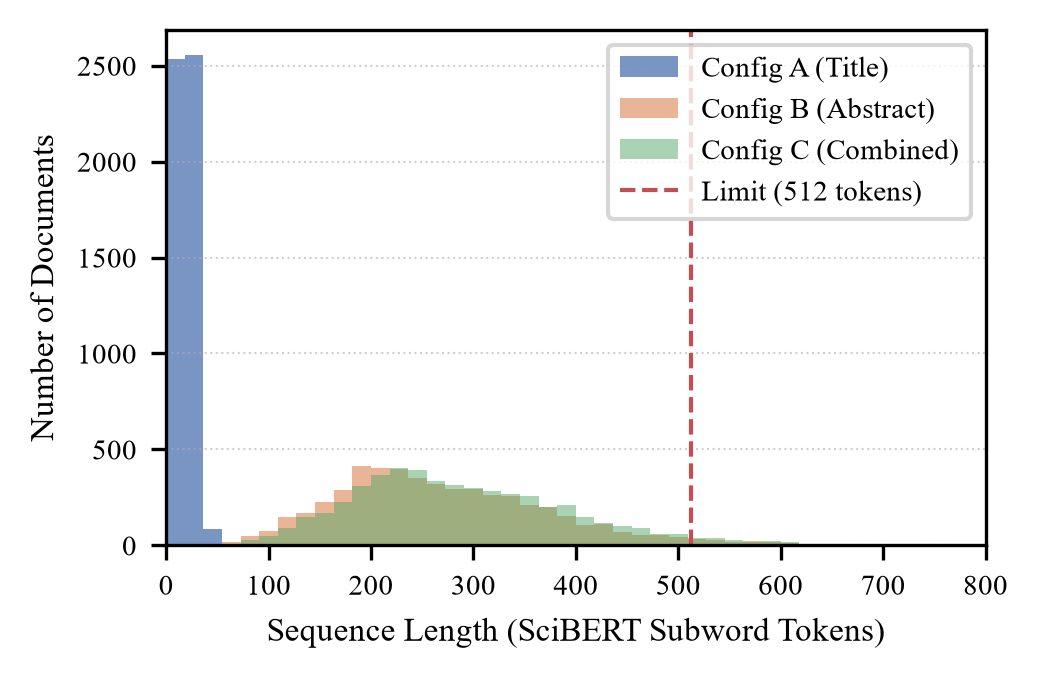

Grafik EDA tersimpan di: D:\tumgas\Kuliah\Semester 5\4. METODOLOGI PENELITIAN\project\metopen-specter2\results\figures\eda_token_length_dist.png


In [5]:
# 4. Visualisasi distribusi panjang token sesuai pakem IEEE (1 kolom: 3.5 inci, 300 DPI, Times New Roman 8 pt)
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
})

fig, ax = plt.subplots(figsize=(3.5, 2.3), dpi=300)

bins = np.linspace(0, 800, 45)
ax.hist(lengths_map["Config A (Title)"][0], bins=bins, alpha=0.75, label="Config A (Title)", color="#4C72B0")
ax.hist(lengths_map["Config B (Abstract)"][0], bins=bins, alpha=0.60, label="Config B (Abstract)", color="#DD8452")
ax.hist(lengths_map["Config C (Title + [SEP] + Abstract)"][0], bins=bins, alpha=0.50, label="Config C (Combined)", color="#55A868")
ax.axvline(MAX_TOKEN_LIMIT, color="#C44E52", linestyle="--", linewidth=1.0, label="Limit (512 tokens)")

ax.set_xlabel("Sequence Length (SciBERT Subword Tokens)")
ax.set_ylabel("Number of Documents")
ax.set_xlim(0, 800)
ax.grid(axis="y", linestyle=":", linewidth=0.5, alpha=0.6)
ax.legend(frameon=True, loc="upper right")
fig.tight_layout()

fig.savefig(FIGURES_DIR / "eda_token_length_dist.png", dpi=300)
fig.savefig(FIGURES_DIR / "eda_token_length_dist.pdf")
plt.show()
print("Grafik EDA tersimpan di:", FIGURES_DIR / "eda_token_length_dist.png")